In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [180]:
from scipy.special import jv, ive, spherical_jn
from scipy.integrate import quad
from scipy.interpolate import CubicSpline
from scipy import fft
from math import factorial

In [3]:
import sys
sys.path.append('../src/')
from polybessel import PolyBessel

In [341]:
PB = PolyBessel()

## Gaussian Hankel Transform

#### $$\int_0^\infty x^2 e^{-x^2/s^2} J_\nu(\omega x) dx = \frac{\omega s^4}{4} e^{-s^2\omega^2/4}  $$

In [387]:
nu = 1
sig2 = 5000
f = lambda x: x**2*np.exp(-x**2/sig2)
a, b = 0.0001, 500 # approximating 0 to infinity

Text(0, 0.5, '$f(x)$')

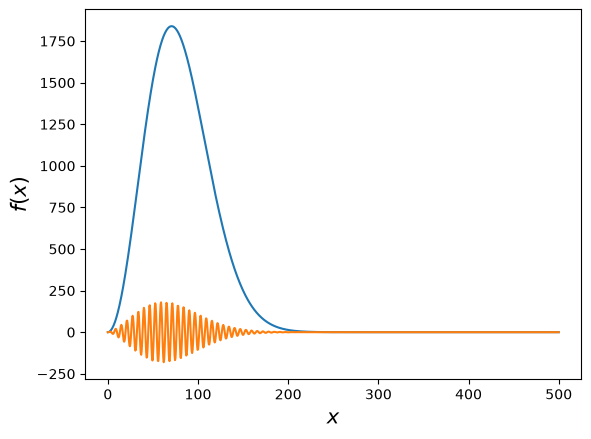

In [388]:
xs = np.linspace(a, b, 1001)
plt.plot(xs, f(xs))
plt.plot(xs, f(xs)*jv(nu, xs))
plt.xlabel('$x$', fontsize=15)
plt.ylabel('$f(x)$', fontsize=15)

In [389]:
ks = np.geomspace(0.001, 0.1, 128)
pb_transform = PB.compute_many_single_bessel(f, [nu], ks, a, b)[0]
true_transform = ks/(2/sig2)**2*np.exp(-ks**2/4*sig2)

In [390]:
from scipy import fft
xlog = np.geomspace(1e-4, 1e4, 256)
dln = np.log(xlog[1]/xlog[0])
mu = nu
offset = fft.fhtoffset(dln, mu)
kfht = np.exp(offset)/xlog[::-1]
scipy_transform = fft.fht(f(xlog), dln, mu, offset=offset) / kfht
scipy_transform_interp = CubicSpline(kfht, scipy_transform)(ks)

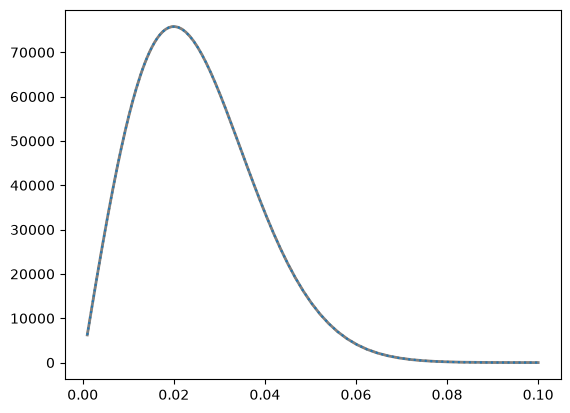

(1e-18, 1)

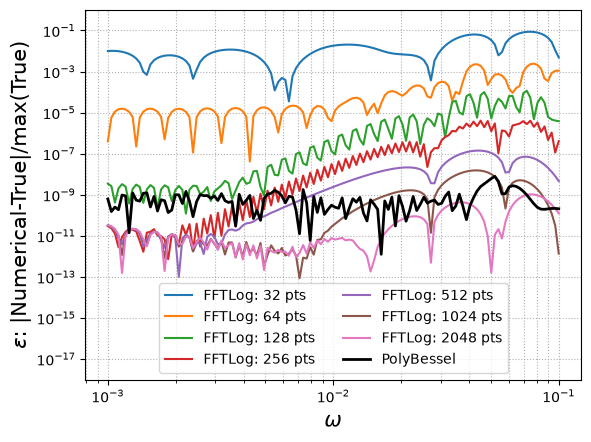

In [395]:

#plt.plot(ks, quad_transform)


plt.plot(ks, scipy_transform_interp, ls='--', c='C1')

plt.plot(ks, true_transform, lw=2, c='grey')

plt.plot(ks, pb_transform, ls=':', c='C0')

#plt.yscale('log')
plt.show()
for n in range(5, 12):
    xlog = np.geomspace(1e-4, 1e4, 2**n)
    dln = np.log(xlog[1]/xlog[0])
    mu = nu
    offset = fft.fhtoffset(dln, mu)
    kfht = np.exp(offset)/xlog[::-1]
    scipy_transform = fft.fht(f(xlog), dln, mu, offset=offset) / kfht
    scipy_transform_interp = CubicSpline(kfht, scipy_transform)(ks)
    plt.plot(ks, np.abs(scipy_transform_interp-true_transform)/true_transform.max(), label='FFTLog: '+str(2**n)+' pts')
plt.plot(ks, np.abs(pb_transform-true_transform)/true_transform.max(), c='k', label='PolyBessel', lw=2)

plt.yscale('log')
plt.grid(which="both", ls=":")
plt.legend(ncol=2, loc='lower center')
plt.xlabel(r'$\omega$', fontsize=15)
plt.ylabel(r'$\epsilon$: |Numerical-True|/max(True)', fontsize=15)
plt.xscale('log')
plt.ylim(1e-18, 1)

In [355]:
%timeit fft.fht(f(xlog), dln, mu, offset=offset) / kfht

112 μs ± 3.06 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [364]:
%timeit pb_transform = PB.compute_many_single_bessel(f, [nu], ks, a, b)[0]

316 μs ± 3.91 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


## Truncated Integral

In [365]:
# truncated integral with exact answer
a, b, nu = 10., 500., 2
g = lambda x: (x/b)**(nu+1)
exact = lambda k: (jv(nu+1, k*b) - (a/b)**(nu+1)*jv(nu+1, k*a))/k

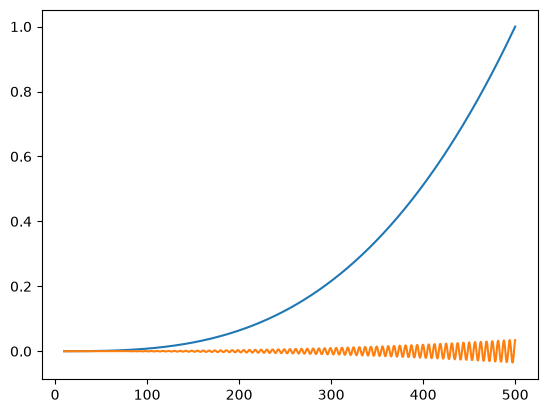

In [368]:
xs = np.linspace(a, b, 1001)
plt.plot(xs, g(xs))
plt.plot(xs, g(xs)*jv(nu, xs))

Text(0, 0.5, 'Max Error: max(|numerical-true|)/max(true)')

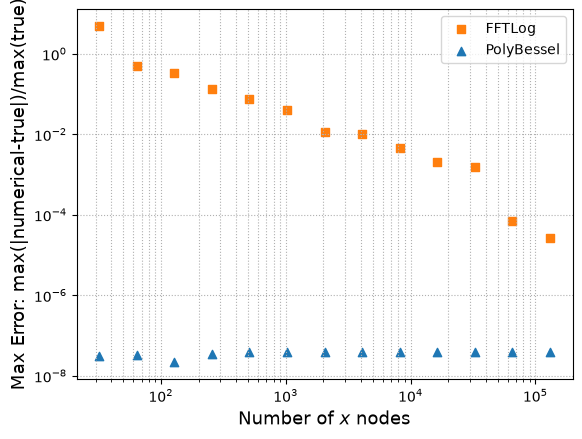

In [396]:
label_on = True
for n in range(5, 18):
    xlog = np.geomspace(1e-1, 5e5, int(2**n)); dln = np.log(xlog[1]/xlog[0])
    off = fft.fhtoffset(dln, nu); kf = np.exp(off)/xlog[::-1]
    F = fft.fht(np.where((xlog >= a) & (xlog <= b), g(xlog), 0.0), dln, nu, offset=off)/kf
    m = (kf >= 0.01) & (kf <= 1.0); k = kf[m]
    P = PB.compute_many_single_bessel(g, [nu], k, a, b)[0]
    #print(2**n, "FFTLog", np.abs(F[m]-exact(k)).max()/np.abs(exact(k)).max(),
    #      "PolyBessel", np.abs(P-exact(k)).max()/np.abs(exact(k)).max())
    if label_on:
        plt.scatter(2**n, np.abs(F[m]-exact(k)).max()/np.abs(exact(k)).max(), c='C1', marker='s', label="FFTLog")
        plt.scatter(2**n, np.abs(P-exact(k)).max()/np.abs(exact(k)).max(), c='C0', marker='^', label="PolyBessel")
        label_on = False
    else:
        plt.scatter(2**n, np.abs(F[m]-exact(k)).max()/np.abs(exact(k)).max(), c='C1', marker='s')
        plt.scatter(2**n, np.abs(P-exact(k)).max()/np.abs(exact(k)).max(), c='C0', marker='^')
plt.xscale('log')
plt.yscale('log')
plt.grid(which="both", ls=":")
plt.legend(loc="best")
plt.xlabel("Number of $x$ nodes", fontsize=13)
plt.ylabel("Max Error: max(|numerical-true|)/max(true)", fontsize=13)

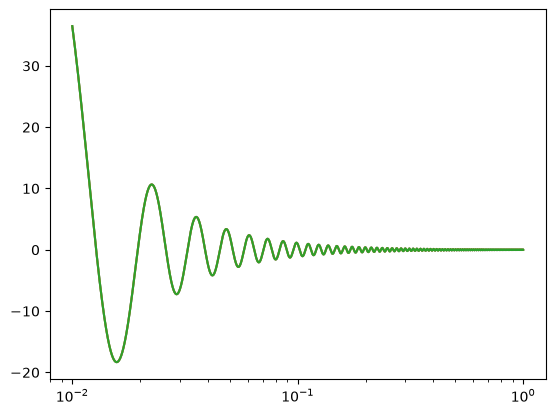

In [376]:
plt.plot(k, exact(k))
plt.plot(k, P)
plt.plot(k, F[m])
plt.xscale('log')

In [82]:
%timeit PB.compute_many_single_bessel(g, [nu], k[::256], a, b)[0]

397 μs ± 1.35 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [81]:
%timeit fft.fht(np.where((xlog >= a) & (xlog <= b), g(xlog), 0.0), dln, nu, offset=off)/kf

3.52 ms ± 27.9 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


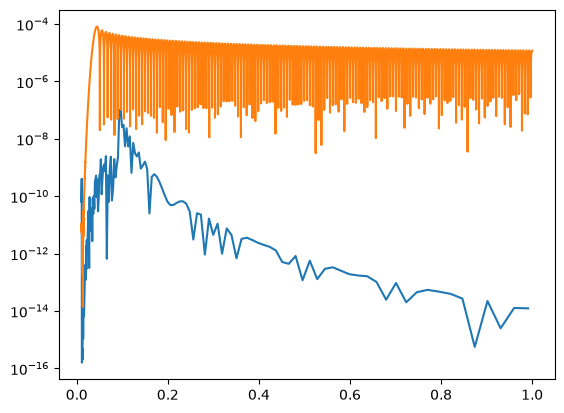

In [32]:
plt.plot(k[::256], np.abs(P[::256]-exact(k[::256]))/np.abs(exact(k[::256])).max())
plt.plot(k, np.abs(F[m]-exact(k))/np.abs(exact(k)).max())
#plt.plot(k, exact(k))
plt.yscale('log')

## Sonine's integral

#### For integer $n\geq 0$,
#### $$ \int_0^1 x^{\ell+2} (1-x^2)^n j_\ell(kx) = \frac{2^n n!}{k^{n+1}} j_{\ell+n+1}(k)$$

In [259]:
PBS = PolyBessel(spherical_bessel=True)

In [417]:
l = 17
n = 3
k_list = np.geomspace(0.01, 100, 1024)
f = lambda x: x**(l+2) * (1-x**2)**n
P = PBS.compute_many_single_bessel(f, [l], k_list, 0.00001, 1)

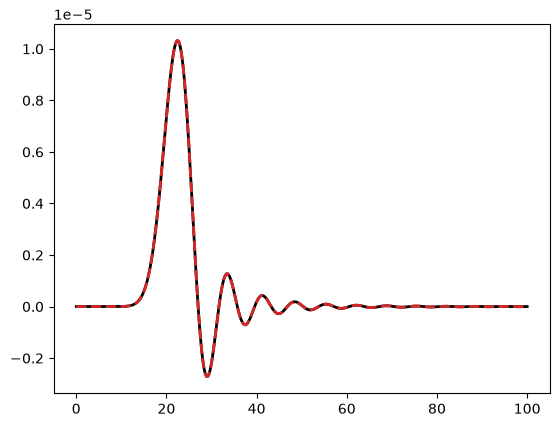

(1e-16, 1)

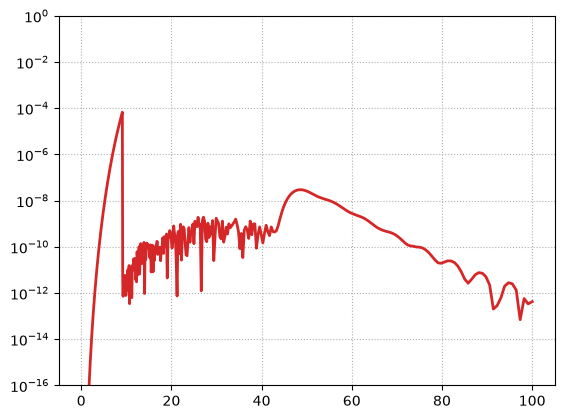

In [418]:
true_transform = spherical_jn(l+n+1, k_list)/k_list**(n+1)*2**n*factorial(n)
plt.plot(k_list, true_transform, c='k', lw=2)
plt.plot(k_list, P[0], ls="--", c='C3', lw=2)

plt.show()

plt.plot(k_list, np.abs(P[0]-true_transform)/np.max(true_transform), c='C3', lw=2)
plt.yscale('log')
plt.grid(which="both", ls=":")
plt.ylim(1e-16, 1)

## Weber's second exponential integral

#### $$ \int_0^\infty x e^{-x^2/s} J_{\nu}(\omega_1 x) J_{\nu}(\omega_2 x) dx = \frac{s}{2}e^{-(\omega_1+\omega_2)^2/4s} I_\nu\left(\frac{s\omega_1\omega_2}{2}\right) $$

In [378]:
# double Bessel vs Weber's second exponential integral
s, nu = 5000., 10
a, b = 1e-4, 300. # ~ 0 to infty
f2 = lambda x: x*np.exp(-x**2/s)
ks = np.geomspace(0.05, 1.0, 512)
W = s/2*np.exp(-(ks[:, None]-ks[None, :])**2*s/4)*ive(nu, ks[:, None]*ks[None, :]*s/2)
P2 = PB.compute_many_double_bessel(f2, [nu], ks, [nu], ks, a, b)[0, :, 0, :]
print("PolyBessel maximal error: ", np.abs(P2-W).max()/np.abs(W).max())

PolyBessel maximal error:  1.1091037785488174e-05


In [379]:
%timeit PB.compute_many_double_bessel(f2, [nu], ks, [nu], ks, a, b)[0, :, 0, :]

1.04 s ± 9.88 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [318]:
878e-3/P2.size

3.34930419921875e-06

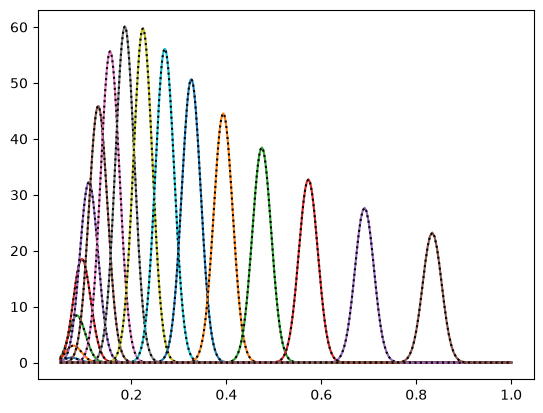

In [380]:
for ci, i in enumerate(range(0, 512, 32)):
    plt.plot(ks, (W)[:, i], c='C'+str(ci))
    plt.plot(ks, (P2)[:, i], c='k', ls=":")

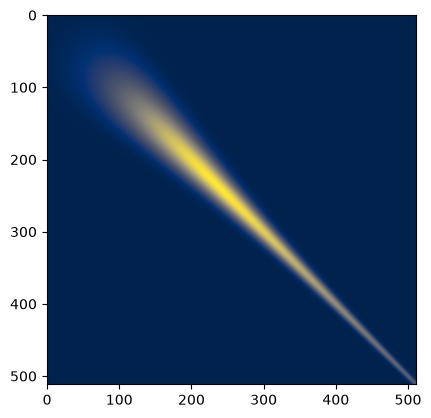

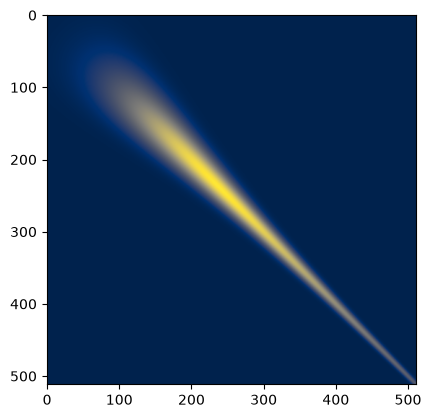

In [381]:
plt.imshow(P2, cmap="cividis")
plt.show()
plt.imshow(W, cmap="cividis")

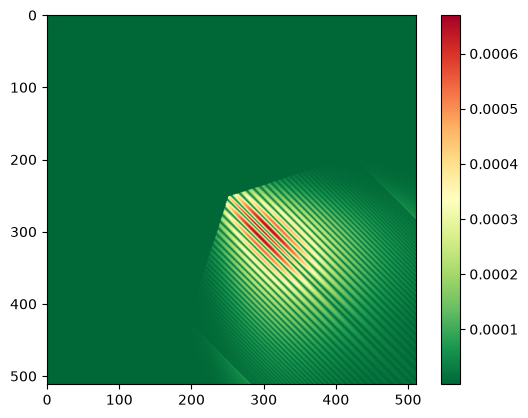

In [382]:
plt.imshow(np.abs(P2-W), cmap="RdYlGn_r")
plt.colorbar()